In [16]:
!pip install xgboost

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import kagglehub
import xgboost as xgb
import seaborn as sns

from sklearn.metrics import mean_squared_error
# from xgboost.callback import EarlyStopping
# from sklearn.model_selection import train_test_split
# from sklearn.preprocessing import StandardScaler

In [18]:
path = kagglehub.dataset_download("robikscube/hourly-energy-consumption")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'hourly-energy-consumption' dataset.
Path to dataset files: /kaggle/input/hourly-energy-consumption


In [19]:
import os

# List the contents of the downloaded directory to find the CSV file
files_in_path = os.listdir(path)

# Assuming there's only one CSV file or we need to find the relevant one
csv_file = [f for f in files_in_path if f.endswith('.csv')][0]
full_csv_path = os.path.join(path, csv_file)

df= pd.read_csv(full_csv_path)

In [20]:
df.shape

(116189, 2)

In [21]:
df = df.set_index('Datetime')
# Sets the Datetime col as the index

In [22]:
df.index.dtype
# It is a simple range of integers although it is a date time
# We need to change the type

dtype('O')

In [23]:
df.index = pd.to_datetime(df.index)
df.sort_index(inplace=True)
# We change the dtype of index col

In [24]:
df.index

DatetimeIndex(['2005-05-01 01:00:00', '2005-05-01 02:00:00',
               '2005-05-01 03:00:00', '2005-05-01 04:00:00',
               '2005-05-01 05:00:00', '2005-05-01 06:00:00',
               '2005-05-01 07:00:00', '2005-05-01 08:00:00',
               '2005-05-01 09:00:00', '2005-05-01 10:00:00',
               ...
               '2018-08-02 15:00:00', '2018-08-02 16:00:00',
               '2018-08-02 17:00:00', '2018-08-02 18:00:00',
               '2018-08-02 19:00:00', '2018-08-02 20:00:00',
               '2018-08-02 21:00:00', '2018-08-02 22:00:00',
               '2018-08-02 23:00:00', '2018-08-03 00:00:00'],
              dtype='datetime64[ns]', name='Datetime', length=116189, freq=None)

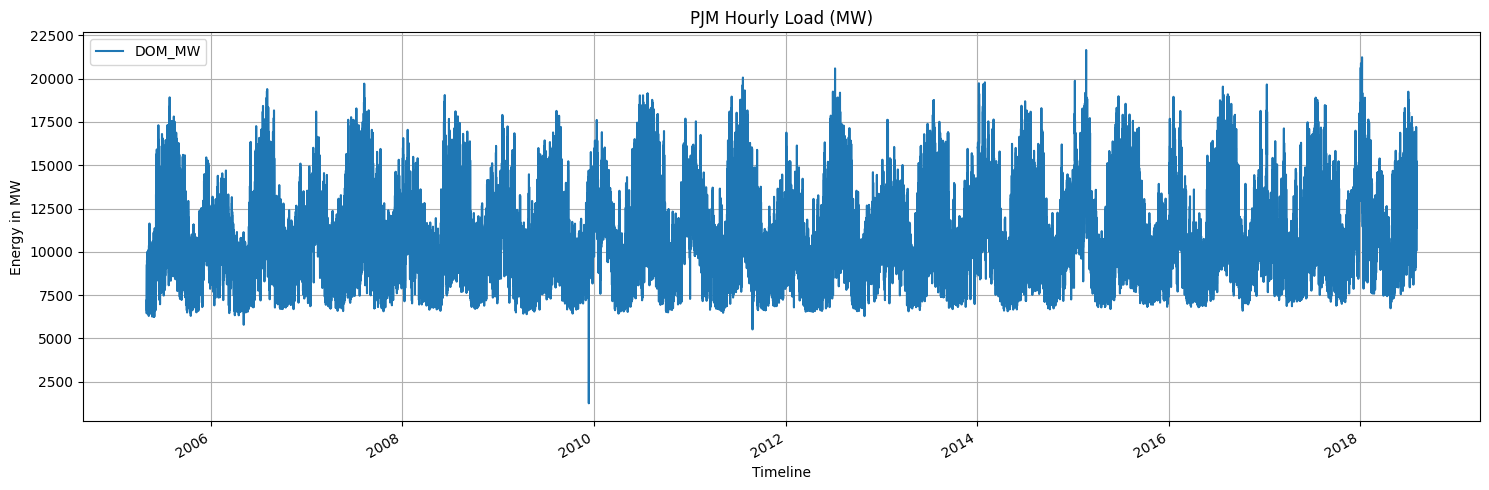

In [25]:
df.plot(figsize=(15, 5),
        title='PJM Hourly Load (MW)',
        ylabel='Energy in MW',
        xlabel='Timeline',
        grid=True)
plt.tight_layout()
plt.show()

In [26]:
df.index[0]

Timestamp('2005-05-01 01:00:00')

In [27]:
str(df.index[-5])[:10] # Accessing the fifth to last element of the DatetimeIndex

'2018-08-02'

First Date- 31 Dec 2005   
Last Date- 1 Jan 2018

So 10 years. Let's divide the first 80% of data as Training and the rest as testing

In [28]:
len(df)

116189

In [29]:
train_lim= 80*len(df)//100
train_lim

92951

In [30]:
y=df['DOM_MW']

In [31]:
train = df.iloc[:train_lim]
test = df.iloc[train_lim:]

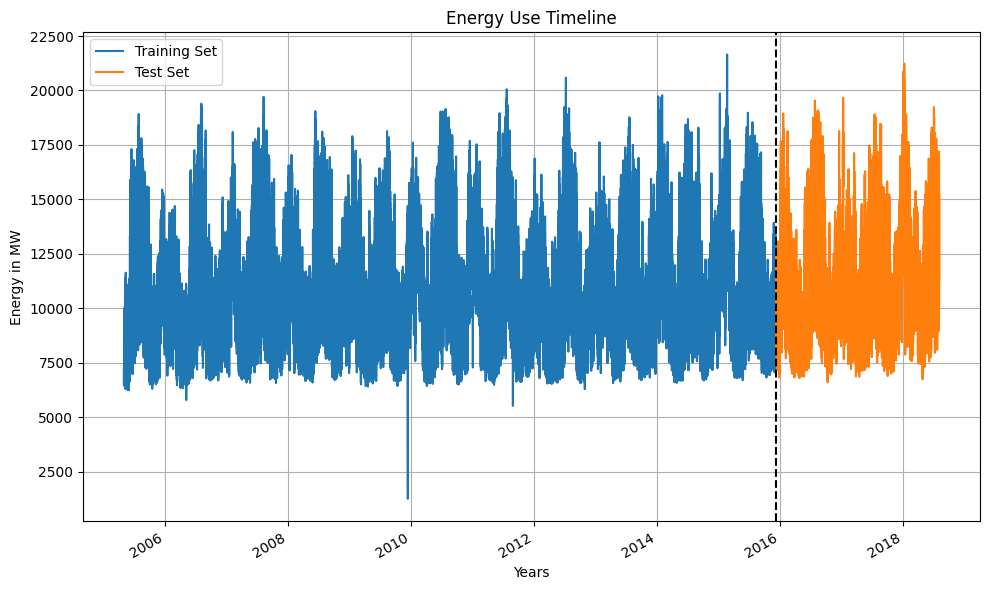

In [32]:
fig, ax = plt.subplots(figsize=(10,6))

train.plot(ax=ax, label='Training Set', title='Energy Use Timeline')
test.plot(ax=ax, label='Test Set')
ax.legend(['Training Set', 'Test Set'])

# The x-coordinate should be the last index of the training set (which is a datetime object)
split_point_x = train.index[-1]
ax.axvline(x=split_point_x, color='black', linestyle='--') # Using axvline with the correct x-value

plt.grid()
plt.xlabel('Years')
plt.ylabel('Energy in MW')
plt.tight_layout()
plt.show()

Checking a week's data

In [33]:
week = df.loc['2010-01-21':'2010-01-28']

<Axes: xlabel='Datetime'>

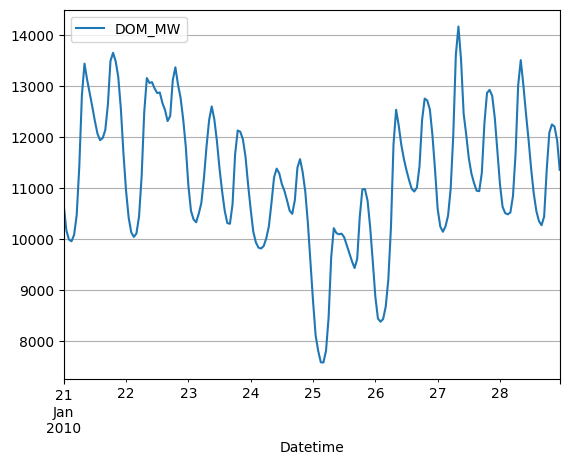

In [34]:
week.plot(grid=True)

## Feature engineering — what changed and why

Below we keep the same calendar features (add is_weekend, which is a part of dayofweek) and then add **lag and rolling-mean features** in the next section.

In [35]:
def create_features(df):
    df = df.copy()
    df['hour'] = df.index.hour
    df['dayofweek'] = df.index.dayofweek
    df['quarter'] = df.index.quarter
    df['month'] = df.index.month
    df['year'] = df.index.year
    df['dayofyear'] = df.index.dayofyear
    df['is_weekend'] = (df.index.dayofweek >= 5).astype(int) # making it int instead of boolean
    return df

df = create_features(df)
df.head()

,DOM_MW,hour,dayofweek,quarter,month,year,dayofyear,is_weekend
Datetime,,,,,,,,
2005-05-01 01:00:00,7190.0,1,6,2,5,2005,121,1
2005-05-01 02:00:00,6803.0,2,6,2,5,2005,121,1
2005-05-01 03:00:00,6583.0,3,6,2,5,2005,121,1
2005-05-01 04:00:00,6452.0,4,6,2,5,2005,121,1
2005-05-01 05:00:00,6445.0,5,6,2,5,2005,121,1


Monthly usage of a random year (say 2012)

[]

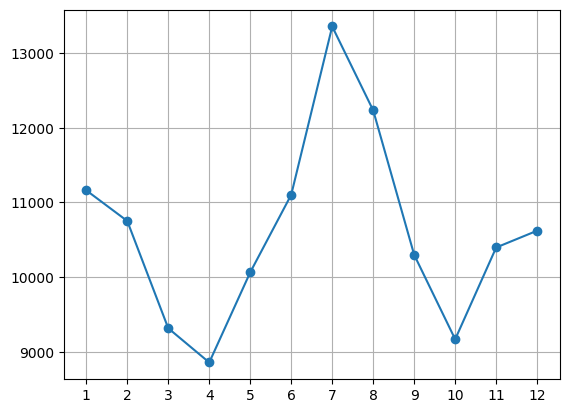

In [36]:
year_2012=df[df['year']==2012]

monthly_avg= year_2012.groupby('month')['DOM_MW'].mean()
monthly_avg

plt.plot(monthly_avg.index, monthly_avg, marker='o')
plt.xticks(monthly_avg.index)
plt.grid()
plt.plot()
# year_2006['month'].plot(figsize=(15, 5), title='PJM Hourly Load (MW)', ylabel='Energy in MW', xlabel='Timeline', grid=True)
# plt.tight_layout()
# plt.show()

Hourly

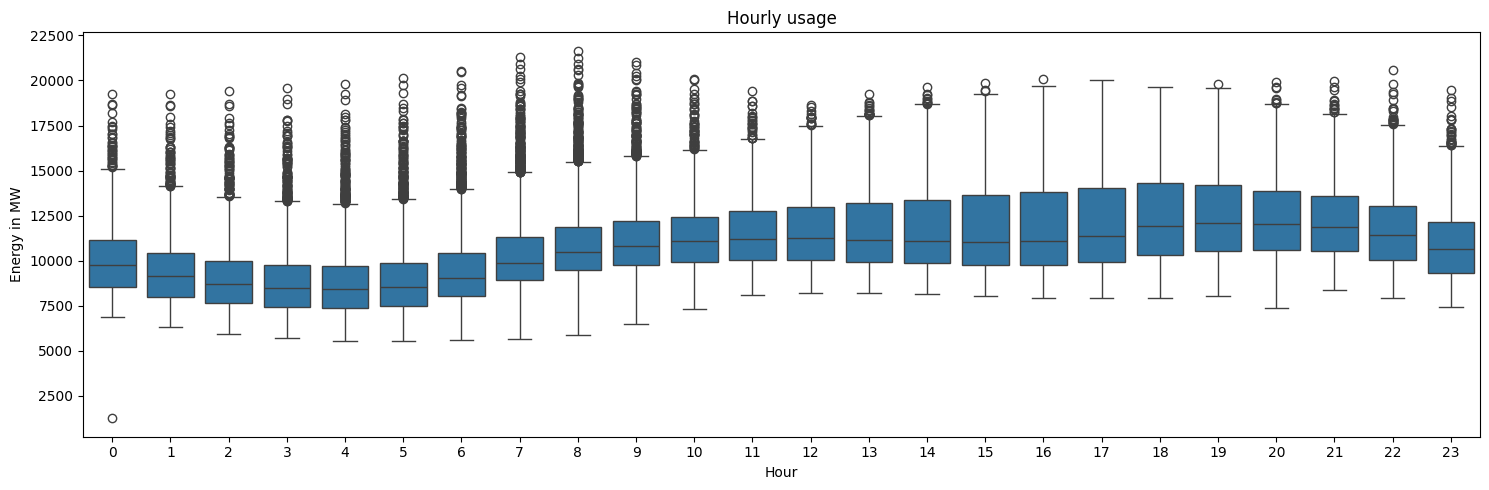

In [37]:
fig, ax= plt.subplots(figsize=(15, 5))
sns.boxplot(data=df, x='hour', y='DOM_MW')
ax.set_title('Hourly usage')
ax.set_xlabel('Hour')
ax.set_ylabel('Energy in MW')
plt.tight_layout()
plt.show()


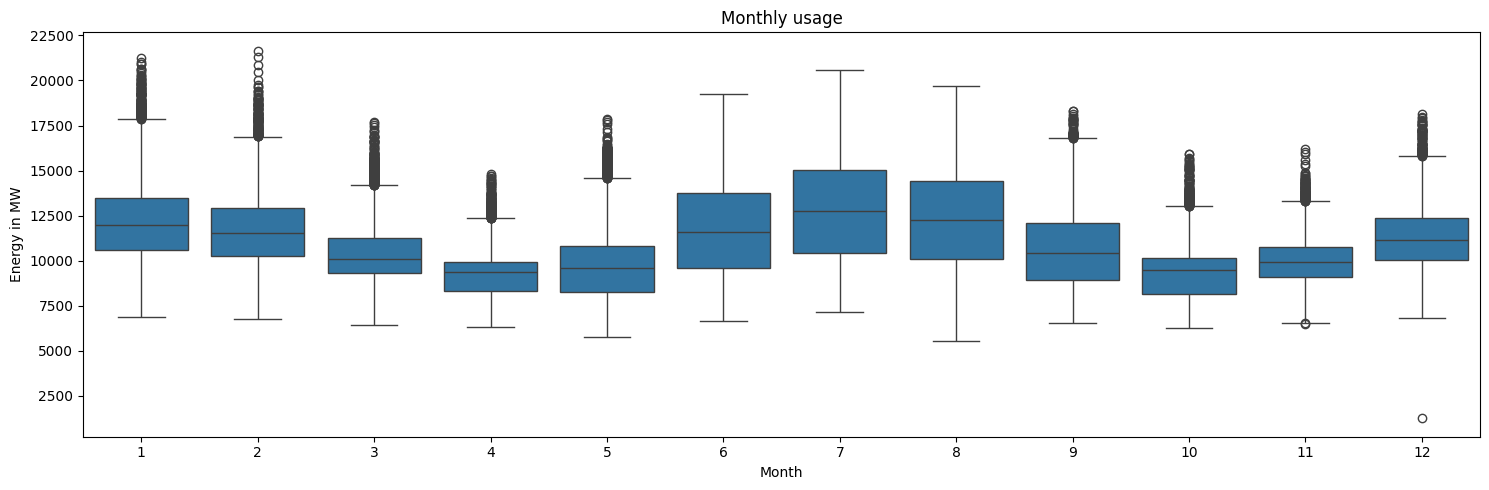

In [38]:
fig, ax= plt.subplots(figsize=(15, 5))
sns.boxplot(data=df, x='month', y='DOM_MW')
ax.set_title('Monthly usage')
ax.set_xlabel('Month')
ax.set_ylabel('Energy in MW')
plt.tight_layout()
plt.show()


In [39]:
df.columns

Index(['DOM_MW', 'hour', 'dayofweek', 'quarter', 'month', 'year', 'dayofyear',
       'is_weekend'],
      dtype='object')

## Lag & rolling-mean features (the main fix)

Energy load is highly **autocorrelated**: the load an hour ago, a day ago, and a week ago are all strong predictors of the load right now. We add:

- `lag_1`   — value 1 hour ago
- `lag_24`  — value 24 hours (1 day) ago, same hour yesterday
- `lag_168` — value 168 hours (1 week) ago, same hour same weekday last week
- `rolling_mean_24`  — average of the last 24 hours (smoothed recent level)
- `rolling_mean_168` — average of the last 7 days (smoothed weekly level)

**Important — no leakage:** every rolling/lag value is computed using `.shift(1)` first, so a row's features only ever use information that was available *before* that timestamp. The first 168 rows of the dataset don't have a full week of history yet, so they get `NaN`s and are dropped with `dropna()`. This is standard practice and only removes a tiny sliver (168 hours) from a 10-year, 100k+ row dataset.

In [40]:
def add_lag_features(df, target_col):
    df = df.copy()
    df['lag_1']   = df[target_col].shift(1)
    df['lag_24']  = df[target_col].shift(24)
    df['lag_168'] = df[target_col].shift(168)
    df['rolling_mean_24']  = df[target_col].shift(1).rolling(24).mean()
    df['rolling_mean_168'] = df[target_col].shift(1).rolling(168).mean()
    return df

df = add_lag_features(df, 'DOM_MW')

In [41]:
print('Rows before dropping warm-up NaNs:\n', len(df))
df = df.dropna()
print('Rows after: \n', len(df))
# df.head()

Rows before dropping warm-up NaNs:
 116189
Rows after: 
 116021


## Train / validation / test split

- **train (70%)** — fit the model
- **validation (15%)** — used only for early stopping
- **test (15%)** — used only once, at the end

All splits stay in time order (no shuffling), which is required for time series.

In [42]:
n = len(df)
train_end = int(n * 0.70)
val_end   = int(n * 0.85)

train = df.iloc[:train_end]
val   = df.iloc[train_end:val_end]
test  = df.iloc[val_end:]

print(f'Train: {len(train)} rows  ({train.index.min()} -> {train.index.max()})')
print(f'Val:   {len(val)} rows  ({val.index.min()} -> {val.index.max()})')
print(f'Test:  {len(test)} rows  ({test.index.min()} -> {test.index.max()})')

Train: 81214 rows  (2005-05-08 01:00:00 -> 2014-08-13 17:00:00)
Val:   17403 rows  (2014-08-13 18:00:00 -> 2016-08-07 20:00:00)
Test:  17404 rows  (2016-08-07 21:00:00 -> 2018-08-03 00:00:00)


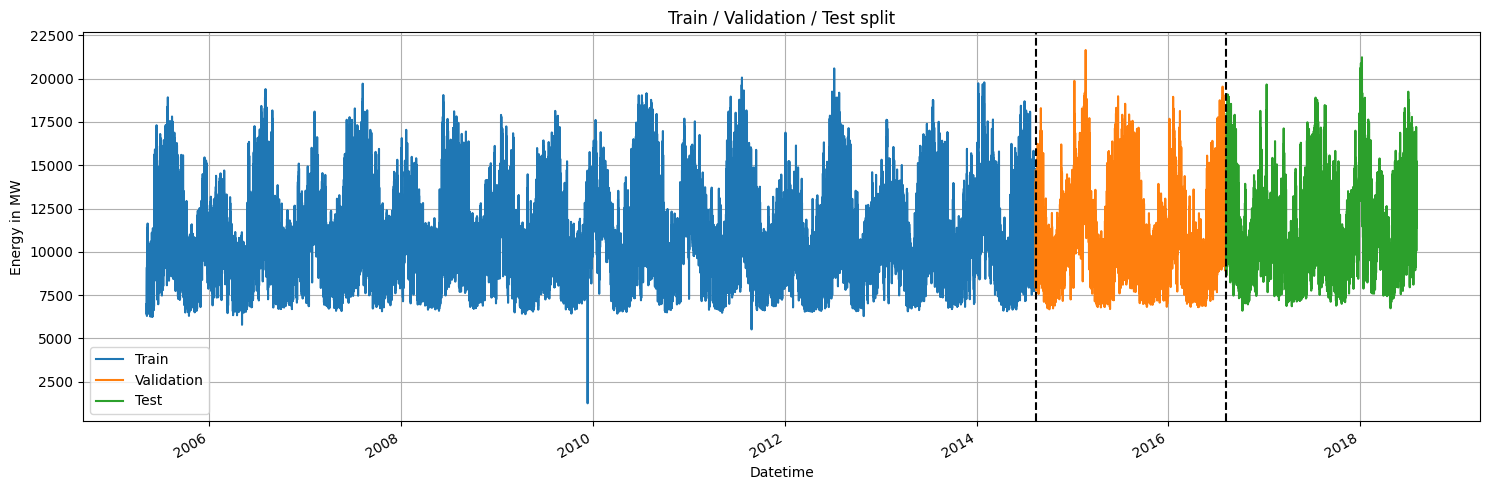

In [43]:
fig, ax = plt.subplots(figsize=(15, 5))
train['DOM_MW'].plot(ax=ax, label='Train')
val['DOM_MW'].plot(ax=ax, label='Validation')
test['DOM_MW'].plot(ax=ax, label='Test')
ax.axvline(train.index[-1], color='black', linestyle='--')
ax.axvline(val.index[-1], color='black', linestyle='--')
ax.legend()
ax.set_title('Train / Validation / Test split')
ax.set_ylabel('Energy in MW')
plt.grid()
plt.tight_layout()
plt.show()

In [44]:
y_train=train['DOM_MW']
y_val=val['DOM_MW']
y_test = test['DOM_MW']

X_train = train.drop(columns=['DOM_MW'])
X_val   = val.drop(columns=['DOM_MW'])
X_test  = test.drop(columns=['DOM_MW'])

In [45]:
X_train.columns

Index(['hour', 'dayofweek', 'quarter', 'month', 'year', 'dayofyear',
       'is_weekend', 'lag_1', 'lag_24', 'lag_168', 'rolling_mean_24',
       'rolling_mean_168'],
      dtype='object')

## Building the regression model


In [46]:
reg = xgb.XGBRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=50,
)

reg.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=100,
)

print('Best iteration:', reg.best_iteration)

[0]	validation_0-rmse:2266.44157	validation_1-rmse:2379.70025
[100]	validation_0-rmse:250.51544	validation_1-rmse:261.05945
[200]	validation_0-rmse:185.52791	validation_1-rmse:200.94377
[300]	validation_0-rmse:164.00881	validation_1-rmse:185.72469
[400]	validation_0-rmse:152.72203	validation_1-rmse:179.25965
[500]	validation_0-rmse:145.30402	validation_1-rmse:175.84477
[600]	validation_0-rmse:138.94639	validation_1-rmse:173.55470
[700]	validation_0-rmse:134.17093	validation_1-rmse:172.39544
[800]	validation_0-rmse:129.78161	validation_1-rmse:171.01987
[900]	validation_0-rmse:126.19772	validation_1-rmse:170.47390
[999]	validation_0-rmse:122.77947	validation_1-rmse:169.72511
Best iteration: 999


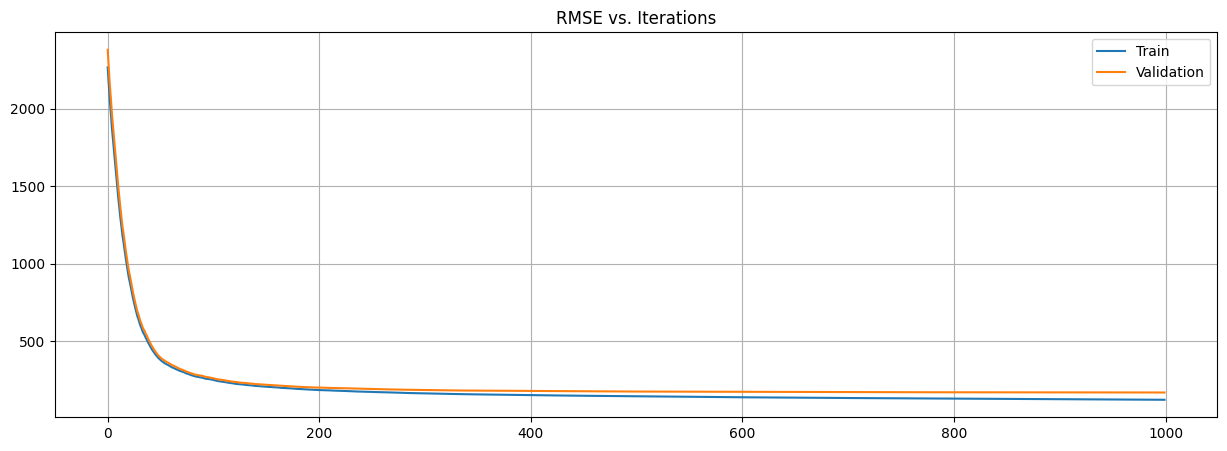

In [47]:
# type(reg.evals_result_)
# reg.evals_result_.keys()

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(reg.evals_result_['validation_0']['rmse'], label='Train')
ax.plot(reg.evals_result_['validation_1']['rmse'], label='Validation')
plt.xlabel='Iterations'
plt.ylabel='RMSE'
plt.title('RMSE vs. Iterations')
plt.grid()
plt.legend()
plt.tight_layout
plt.show()

In [48]:
y_pred = reg.predict(X_test)
residuals = y_test - y_pred
y_pred[:5]

array([14234.421, 13522.192, 12405.73 , 11174.011, 10289.189],
      dtype=float32)

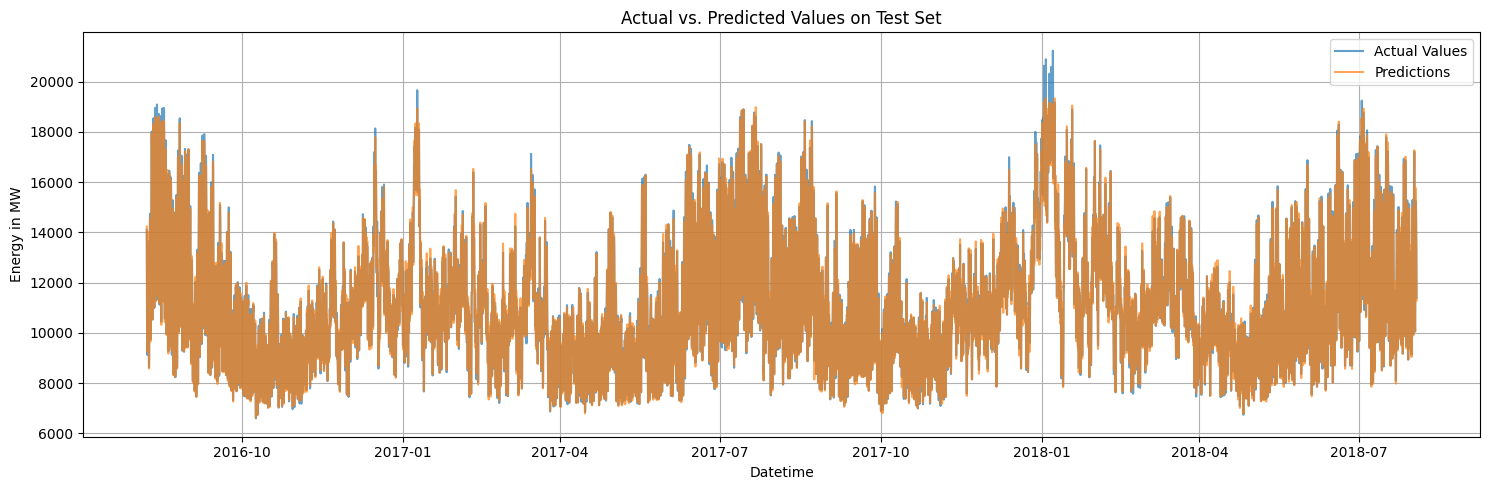

In [49]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(y_test.index, y_test, label='Actual Values', alpha=0.7)
ax.plot(y_test.index, y_pred, label='Predictions', alpha=0.7)
ax.set_title('Actual vs. Predicted Values on Test Set')
ax.set_xlabel('Datetime')
ax.set_ylabel('Energy in MW')
ax.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

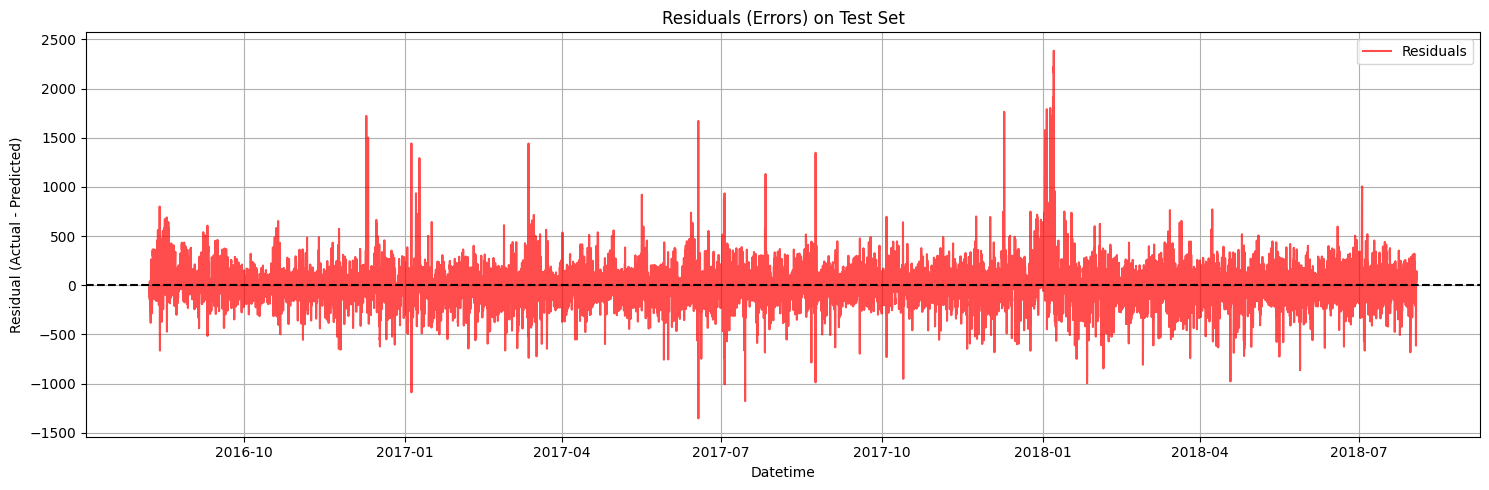

In [50]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(y_test.index, residuals, label='Residuals', color='red', alpha=0.7)
ax.axhline(y=0, color='black', linestyle='--')
ax.set_title('Residuals (Errors) on Test Set')
ax.set_xlabel('Datetime')
ax.set_ylabel('Residual (Actual - Predicted)')
ax.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [51]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print('Single-model performance on held-out TEST set')
print('---------------------------------------------')
print(f'MAE  : {mae:.2f} MW')
print(f'RMSE : {rmse:.2f} MW')
print(f'R\u00b2   : {r2:.4f}')

Single-model performance on held-out TEST set
---------------------------------------------
MAE  : 132.38 MW
RMSE : 192.18 MW
R²   : 0.9939


### Naive baseline

Before trusting the R², it's worth comparing against the simplest possible forecast: "predict the same value as one hour ago" (`lag_1`). If our model can't beat this, it isn't adding value.

In [52]:
baseline_pred = X_test['lag_1']

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = mean_squared_error(y_test, baseline_pred) ** 0.5
baseline_r2 = r2_score(y_test, baseline_pred)

print('Naive Lag-1 Baseline')
print(f'MAE : {baseline_mae:.2f} MW')
print(f'RMSE: {baseline_rmse:.2f} MW')
print(f'R\u00b2  : {baseline_r2:.4f}')

Naive Lag-1 Baseline
MAE : 411.26 MW
RMSE: 517.31 MW
R²  : 0.9555


# Hyperparameter tuning with GridSearchCV

To squeeze out a bit more performance we tune hyperparameters with `GridSearchCV` using `TimeSeriesSplit` (so every fold still respects chronological order — no shuffling, no future leaking into the past).

**Important:** the grid search only ever sees `train + val` combined (never `test`). The held-out `test` set is evaluated exactly once at the very end, with the best model the search finds.

In [53]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

trainval = pd.concat([train, val])
y_trainval = trainval['DOM_MW']
X_trainval = trainval.drop(columns=['DOM_MW'])

tscv = TimeSeriesSplit(n_splits=5)

Fold 1:
TRAIN TRAIN | VALIDATION

Fold 2:
TRAIN TRAIN TRAIN | VALIDATION

Fold 3:
TRAIN TRAIN TRAIN TRAIN | VALIDATION

Fold 4:
TRAIN TRAIN TRAIN TRAIN TRAIN | VALIDATION

Fold 5:
TRAIN TRAIN TRAIN TRAIN TRAIN TRAIN | VALIDATION

In [54]:
param_grid = {
    'n_estimators': [300, 600, 800],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [None, 4, 6],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
}

In [55]:
grid_search = GridSearchCV(
    estimator=xgb.XGBRegressor(
        objective='reg:squarederror',
        random_state=42,
        n_jobs=-1,
    ),
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=1,
)

grid_search.fit(X_trainval, y_trainval)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


GridSearchCV(cv=TimeSeriesSplit(gap=0, max_train_size=None, n_splits=5, test_size=None),
             estimator=XGBRegressor(base_score=None, booster=None,
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping_rounds=None,
                                    enable_categorical=True, eval_metric=None,
                                    feature_types=None, feature_weights=None,
                                    gamma=None,...
                                    max_depth=None, max_leaves=None,
                                    min_child_weight=None, missing=nan,
                                    monotone_constraints=None,
                                    multi_strategy=None, n_estimators=None,
                                    n_jobs=-1, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.8, 1.0],
                         'learning_rate': [0.03, 0.05, 0.1],
                         'max_depth': [None, 4, 6],
                         'n_estimators': [300, 600, 800],
                         'subsample': [0.8, 1.0]},
             scoring='neg_root_mean_squared_error', verbose=1)

In [56]:
print('Best Parameters:')
print(grid_search.best_params_)

Best Parameters:
{'colsample_bytree': 1.0, 'learning_rate': 0.05, 'max_depth': None, 'n_estimators': 800, 'subsample': 0.8}


In [57]:
print('Best CV RMSE:')
print(-grid_search.best_score_)

Best CV RMSE:
175.31872768944044


Scikit-learn's GridSearchCV convention treats higher scores as better, so error metrics such as RMSE are represented as negative values.

In [58]:
best_model = grid_search.best_estimator_
print(best_model)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=1.0, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=800,
             n_jobs=-1, num_parallel_tree=None, ...)


### Final, one-time evaluation on the test set

In [59]:
final_pred = best_model.predict(X_test)

mse = mean_squared_error(y_test, final_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, final_pred)
r2 = r2_score(y_test, final_pred)

print('Final Tuned Model Performance (TEST set)')
print('-----------------------------------------')
print(f'MAE  : {mae:.2f} MW')
print(f'RMSE : {rmse:.2f} MW')
print(f'R\u00b2   : {r2:.4f}')
print()
print('vs. Naive Lag-1 Baseline')
print(f'MAE  : {baseline_mae:.2f} MW')
print(f'RMSE : {baseline_rmse:.2f} MW')
print(f'R\u00b2   : {baseline_r2:.4f}')

Final Tuned Model Performance (TEST set)
-----------------------------------------
MAE  : 121.73 MW
RMSE : 181.15 MW
R²   : 0.9945

vs. Naive Lag-1 Baseline
MAE  : 411.26 MW
RMSE : 517.31 MW
R²   : 0.9555


### Feature importance

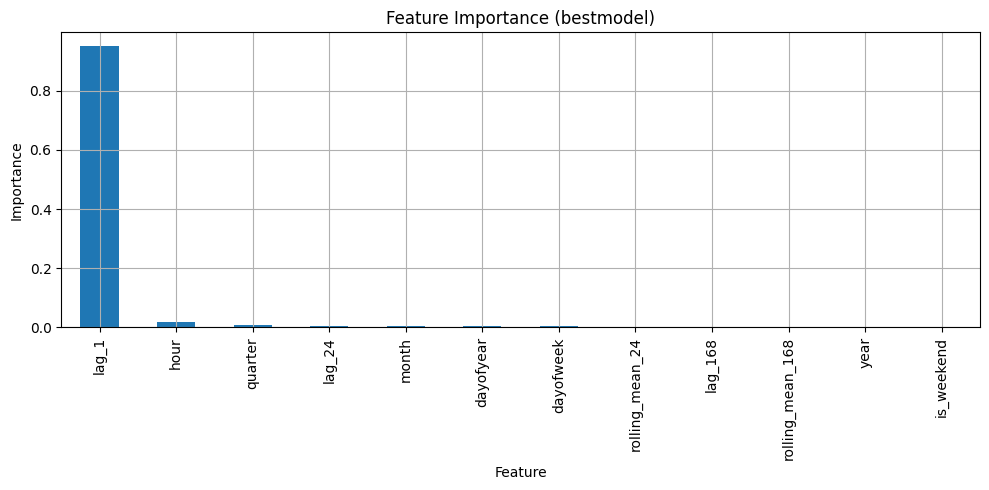

,0
lag_1,0.949144
hour,0.019718
quarter,0.009022
lag_24,0.006212
month,0.004990
dayofyear,0.003736
dayofweek,0.003319
rolling_mean_24,0.001865
lag_168,0.001113
rolling_mean_168,0.000511


In [60]:
importances = pd.Series(best_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
importances.plot(kind='bar', ax=ax)
ax.set_title('Feature Importance (bestmodel)')
ax.set_ylabel('Importance')
ax.set_xlabel('Feature')
plt.grid()
plt.tight_layout()
plt.show()

importances